In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('german_credit.csv')
print("Boyut:", df.shape)
print("\nSınıf dağılımı:")
print(df['class'].value_counts())
df.head()

Boyut: (1000, 21)

Sınıf dağılımı:
class
good    700
bad     300
Name: count, dtype: int64


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [4]:
y = (df['class'] == 'bad').astype(int)   # bad -> 1 (Risk), good -> 0 (Safe)
X = df.drop(columns='class')
print(y.value_counts())

class
0    700
1    300
Name: count, dtype: int64


In [5]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print("Sayısal:", num_cols)
print("Kategorik:", cat_cols)

Sayısal: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Kategorik: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


In [6]:
# Önce test'i ayır (%20)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Kalanı train/validation olarak böl (%75/%25 -> toplamda %60/%20)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print("Eğitim:", len(X_train), "Risk oranı:", round(y_train.mean(), 2))
print("Validation:", len(X_val), "Risk oranı:", round(y_val.mean(), 2))
print("Test:", len(X_test), "Risk oranı:", round(y_test.mean(), 2))

Eğitim: 600 Risk oranı: 0.3
Validation: 200 Risk oranı: 0.3
Test: 200 Risk oranı: 0.3


In [7]:
def make_preprocessor():
    num = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler())
    ])
    cat = Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('oh', OneHotEncoder(handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('num', num, num_cols),
        ('cat', cat, cat_cols)
    ])

In [8]:
def metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (1)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (1)': recall_score(y_true, y_pred),
        'F1 (1)': f1_score(y_true, y_pred)
    }

In [9]:
base = Pipeline([
    ('prep', make_preprocessor()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
base.fit(X_train, y_train)

print("Validation:", metrics(y_val, base.predict(X_val)))
print("Test:", metrics(y_test, base.predict(X_test)))

Validation: {'Accuracy': 0.695, 'Precision (1)': 0.49056603773584906, 'Recall (1)': 0.43333333333333335, 'F1 (1)': 0.46017699115044247}
Test: {'Accuracy': 0.75, 'Precision (1)': 0.5862068965517241, 'Recall (1)': 0.5666666666666667, 'F1 (1)': 0.576271186440678}


Karmaşıklık matrisi (satır=gerçek, sütun=tahmin):
[[113  27]
 [ 34  26]]


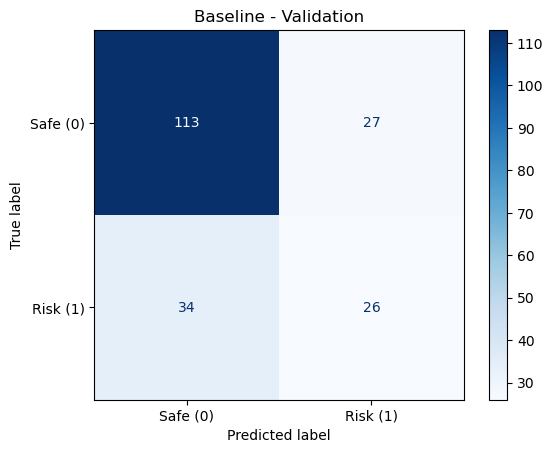

In [10]:
cm = confusion_matrix(y_val, base.predict(X_val))
print("Karmaşıklık matrisi (satır=gerçek, sütun=tahmin):")
print(cm)

disp = ConfusionMatrixDisplay(cm, display_labels=['Safe (0)', 'Risk (1)'])
disp.plot(cmap='Blues')
plt.title('Baseline - Validation')
plt.show()

In [11]:
proba_val = base.predict_proba(X_val)[:, 1]   # Risk olma olasılığı

for esik in [0.2, 0.3, 0.5, 0.7]:
    tahmin = (proba_val >= esik).astype(int)
    p = precision_score(y_val, tahmin, zero_division=0)
    r = recall_score(y_val, tahmin)
    print(f"Eşik {esik}: Precision={p:.2f}, Recall={r:.2f}")

Eşik 0.2: Precision=0.43, Recall=0.78
Eşik 0.3: Precision=0.44, Recall=0.63
Eşik 0.5: Precision=0.49, Recall=0.43
Eşik 0.7: Precision=0.64, Recall=0.27


In [12]:
# Class Weights (Sınıf Ağırlıkları) modeli
cw = Pipeline([
    ('prep', make_preprocessor()),
    # Buradaki sihir: class_weight='balanced'
    ('clf', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

# Modeli eğit
cw.fit(X_train, y_train)

# Sonuçları yazdır
print("Class Weights - Validation:", metrics(y_val, cw.predict(X_val)))
print("Class Weights - Test:", metrics(y_test, cw.predict(X_test)))

Class Weights - Validation: {'Accuracy': 0.63, 'Precision (1)': 0.42045454545454547, 'Recall (1)': 0.6166666666666667, 'F1 (1)': 0.5}
Class Weights - Test: {'Accuracy': 0.71, 'Precision (1)': 0.5111111111111111, 'Recall (1)': 0.7666666666666667, 'F1 (1)': 0.6133333333333333}


In [13]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# Oversampling işlemini pipeline'ın içine koyuyoruz ki sadece eğitim verisine uygulansın
ros = ImbPipeline([
    ('prep', make_preprocessor()),
    # Sadece eğitim verisinde riskli sınıfı çoğaltır
    ('ros', RandomOverSampler(random_state=42)), 
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

ros.fit(X_train, y_train)

print("Random Oversampling - Validation:", metrics(y_val, ros.predict(X_val)))
print("Random Oversampling - Test:", metrics(y_test, ros.predict(X_test)))

Random Oversampling - Validation: {'Accuracy': 0.625, 'Precision (1)': 0.4117647058823529, 'Recall (1)': 0.5833333333333334, 'F1 (1)': 0.4827586206896552}
Random Oversampling - Test: {'Accuracy': 0.71, 'Precision (1)': 0.5121951219512195, 'Recall (1)': 0.7, 'F1 (1)': 0.5915492957746479}


In [14]:
from imblearn.over_sampling import SMOTENC

# Kategorik sütunların indekslerini buluyoruz (SMOTENC )
cat_indices = [X_train.columns.get_loc(col) for col in cat_cols]

smote = ImbPipeline([
    # Önce veriyi olduğu gibi SMOTE'a veriyoruz (kategorikleri bilmesi için)
    ('smote', SMOTENC(categorical_features=cat_indices, random_state=42)),
    ('prep', make_preprocessor()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

smote.fit(X_train, y_train)

print("SMOTE - Validation:", metrics(y_val, smote.predict(X_val)))
print("SMOTE - Test:", metrics(y_test, smote.predict(X_test)))

SMOTE - Validation: {'Accuracy': 0.65, 'Precision (1)': 0.4305555555555556, 'Recall (1)': 0.5166666666666667, 'F1 (1)': 0.4696969696969697}
SMOTE - Test: {'Accuracy': 0.69, 'Precision (1)': 0.48484848484848486, 'Recall (1)': 0.5333333333333333, 'F1 (1)': 0.5079365079365079}


In [15]:
import pandas as pd

sonuclar = {
    'Baseline: logistic regression': metrics(y_test, base.predict(X_test)),
    'Class weights': metrics(y_test, cw.predict(X_test)),
    'Threshold moving (selected threshold: 0.2)': metrics(y_test, (base.predict_proba(X_test)[:, 1] >= 0.2).astype(int)),
    'Random oversampling': metrics(y_test, ros.predict(X_test)),
    'SMOTE (optional)': metrics(y_test, smote.predict(X_test))
}

# Sözlüğü DataFrame'e çevirip yuvarlayalım
tablo = pd.DataFrame(sonuclar).T.round(2)
tablo.index.name = 'Technique'
tablo

,Accuracy,Precision (1),Recall (1),F1 (1)
Technique,,,,
Baseline: logistic regression,0.75,0.59,0.57,0.58
Class weights,0.71,0.51,0.77,0.61
Threshold moving (selected threshold: 0.2),0.66,0.46,0.85,0.60
Random oversampling,0.71,0.51,0.70,0.59
SMOTE (optional),0.69,0.48,0.53,0.51


1) Hangi teknik Risk sınıfında en yüksek Recall'ı verdi? Precision'a ne oldu?

En yüksek Recall'ı Threshold Moving (eşik 0.2) yöntemi verdi (0.85). Baseline modelde 0.57 olan Recall bu yöntemle 0.85'e çıktı, ancak Precision 0.59'dan 0.46'ya düştü. Yani model riskli müşterilerin çoğunu yakaladı ama karşılığında çok sayıda güvenli müşteriye yanlışlıkla "riskli" dedi. Class Weights yöntemi ise Recall'ı 0.77'ye çıkarırken Precision'ı 0.51'de tuttu ve en yüksek F1 skorunu (0.61) verdi. Bu yüzden Recall ile Precision arasında en dengeli seçenek Class Weights oldu.

2) Bölmeden önce oversampling neden tehlikelidir?

Eğer veriyi train/test olarak bölmeden önce çoğaltma yaparsak, aynı müşterinin kopyaları hem eğitim hem de test setine düşer. Model test aşamasında daha önce gördüğü (ezberlediği) bir müşteriyle karşılaşır. Buna veri sızıntısı (data leakage) denir. Bu durumda modelin test skorları yapay olarak yüksek çıkar ve gerçek dünyada (yeni müşterilerde) model çöker. Bu yüzden önce bölmeli, sadece eğitim verisini çoğaltmalıyız.

3) Banka müdürü olsaydınız Precision ve Recall'ı nasıl dengelerdiniz?

Banka müdürü olsaydım Recall'a öncelik verirdim. Çünkü riskli bir müşteriye kredi vermek (parayı batırmak), güvenli bir müşteriyi reddetmekten (sadece faiz kaybı) çok daha maliyetlidir. Bu yüzden eşiği düşürüp (veya Class Weights kullanıp) riskli müşterilerin çoğunu yakalamayı tercih ederdim. Ancak çok fazla güvenli müşteriyi de kaybetmemek için, iki hatanın (yanlış kredi verme ve yanlış reddetme) maliyetini hesaplayıp optimum bir eşik seçerdim.